<a href="https://colab.research.google.com/github/bfzeigler/svd-image-compression/blob/main/notebooks/02%20svd%20approximation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 2: The SVD and Rank-k Approximation

Names: Bianca Zeigler

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

A = data.camera().astype(float)

print(A.shape, A.dtype)

(512, 512) float64


This image is a matrix with 512 rows and 512 columns. When you convert it to a float it helps prevent the interger overflow that I discussed in Mileston 1.

In [2]:
U, s, Vt = np.linalg.svd(A, full_matrices=False)

print("U:", U.shape, "s:", s.shape, "Vt:", Vt.shape)

A_back = U @ np.diag(s) @ Vt

print("Rebuilt correctly?", np.allclose(A, A_back))
print("Largest error:", np.abs(A - A_back).max())

U: (512, 512) s: (512,) Vt: (512, 512)
Rebuilt correctly? True
Largest error: 2.538058652135078e-11


U, s and Vt contain all the parts of the SVD.
np.diag(s) then places all the singular values on the diagonal of the matrix.
@ then performs the matrix multiplication.
Multiplying the pieces will then reconstruct the original image, apart from any tiny rounding errors.


First five: [70966.  17054.6 13314.9  8837.4  5874.6]
50th, 200th, last: 757.2 175.5 0.006


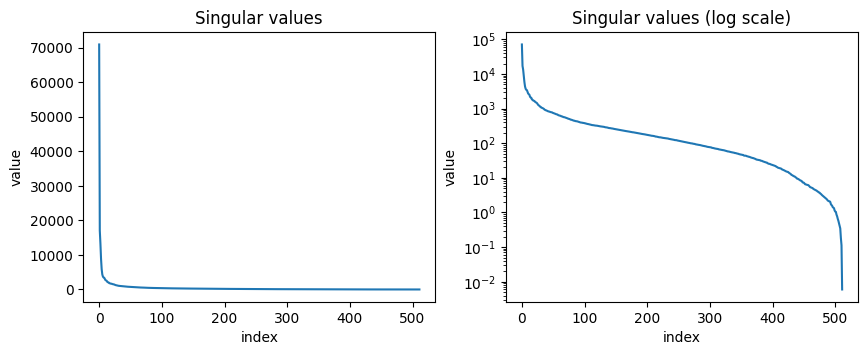

In [3]:
print("First five:", np.round(s[:5], 1))

print(
    "50th, 200th, last:",
    round(s[49], 1),
    round(s[199], 1),
    round(s[-1], 3)
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))

ax1.plot(s)
ax1.set(
    title="Singular values",
    xlabel="index",
    ylabel="value"
)

ax2.semilogy(s)
ax2.set(
    title="Singular values (log scale)",
    xlabel="index",
    ylabel="value"
)

plt.show()

The singular value graph has the points ordered from largest to smallest. The larger the value the more it contributed to the image. The log scale graphs allows you to see the smaller values more.

In [4]:
def rank_k_approx(A, k):
    """Return the rank-k SVD approximation of A."""
    U, s, Vt = np.linalg.svd(A, full_matrices=False)
    return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

U[:, :k] keeps the first k columns of U
s[:k] keeps the first k singular values
Vt[:k, :] keeps the fist k rows of Vt

In [5]:
print(
    "Rank of A_10:",
    np.linalg.matrix_rank(rank_k_approx(A, 10))
)

print(
    "k = 512 gives A back?",
    np.allclose(rank_k_approx(A, 512), A)
)

stripes = np.outer(
    [1, 0, 1, 0],
    [1, 1, 1, 1]
).astype(float)

print(
    "Singular values of stripes:",
    np.round(
        np.linalg.svd(stripes, compute_uv=False),
        4
    )
)

Rank of A_10: 10
k = 512 gives A back? True
Singular values of stripes: [2.8284 0.     0.     0.    ]


Keeping 10 terms will then produce a 10 rank approximation.
Keeping all 512 terms will then reconstruct the original term.
The stripe image has only 1 rank, so it will only have one nonzero singluar value.

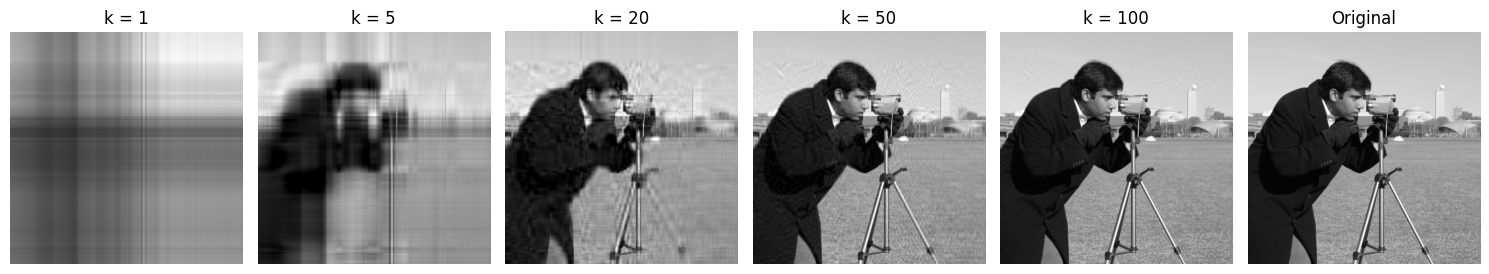

In [6]:
ks = [1, 5, 20, 50, 100]

fig, axes = plt.subplots(
    1,
    len(ks) + 1,
    figsize=(15, 3)
)

for ax, k in zip(axes, ks):
    Ak = np.clip(rank_k_approx(A, k), 0, 255)
    ax.imshow(Ak, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"k = {k}")
    ax.axis("off")

axes[-1].imshow(A, cmap="gray", vmin=0, vmax=255)
axes[-1].set_title("Original")
axes[-1].axis("off")

plt.tight_layout()
plt.show()

As the k value increases, the picture becomes increasingly more clear. The np.clip also keeps the displayed pixel values between 0 and 255. Also, using the same vmin and vmax keeps the brightness the same across the images.

## Exercise 1: Singular values of M

$$
M = \begin{bmatrix}3 & 0 \\ 4 & 5\end{bmatrix}
$$


$$
M^T M =
\begin{bmatrix}3 & 4 \\ 0 & 5\end{bmatrix}
\begin{bmatrix}3 & 0 \\ 4 & 5\end{bmatrix}
=
\begin{bmatrix}25 & 20 \\ 20 & 25\end{bmatrix}
$$

$$
\det(M^T M - \lambda I) = (25-\lambda)^2 - 400 = 0
$$

$$
25-\lambda = \pm 20
$$

$$
\sigma_1 = \sqrt{45} = 3\sqrt{5} \approx 6.7082
$$

$$
\sigma_2 = \sqrt{5} \approx 2.2361
$$

$$
(-u_1)(-v_1)^T = u_1v_1^T
$$

In [7]:
import numpy as np

M = np.array([
    [3, 0],
    [4, 5]
], dtype=float)

U_M, s_M, Vt_M = np.linalg.svd(M)

print("Singular values:", s_M)

Singular values: [6.70820393 2.23606798]


We can see that numpy's values match the square roots of the eigenvalues I calculated

## Exercise 2: Approximation error

In [8]:
A20 = rank_k_approx(A, 20)

image_error = np.linalg.norm(A - A20)
singular_value_error = np.sqrt(np.sum(s[20:]**2))

print("Image approximation error:", image_error)
print("Discarded singular value error:", singular_value_error)

print(
    "Do they agree?",
    np.isclose(image_error, singular_value_error)
)

Image approximation error: 7699.9091419681245
Discarded singular value error: 7699.9091419681245
Do they agree? True


The eckart-young result gives the approximation error as the square root of the sum of the squared discarded singular values.
Python begins indexing at 0, so the first 20 values are s[0] through s[19]. So, s[20:] begins with the first 21st singular value, the first one discarded.

## Exercise 3: Compression of my photograph

In [9]:
from google.colab import files
from PIL import Image

uploaded = files.upload()

Saving ECC39AC4-99D8-4148-87BC-ECF0894196FF.jpeg to ECC39AC4-99D8-4148-87BC-ECF0894196FF (1).jpeg


Photo shape: (800, 600)
Data type: float64


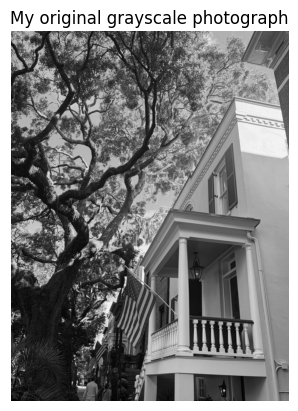

In [10]:
name = list(uploaded)[0]

img = Image.open(name).convert("L")
img.thumbnail((800, 800))

P = np.array(img).astype(float)

print("Photo shape:", P.shape)
print("Data type:", P.dtype)

plt.imshow(P, cmap="gray", vmin=0, vmax=255)
plt.title("My original grayscale photograph")
plt.axis("off")
plt.show()

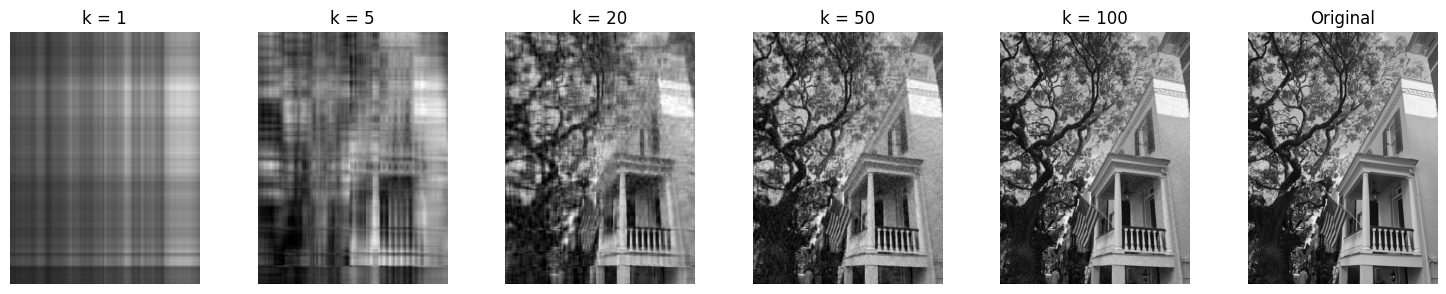

In [11]:
ks_photo = [1, 5, 20, 50, 100]

fig, axes = plt.subplots(
    1,
    len(ks_photo) + 1,
    figsize=(15, 3)
)

for ax, k in zip(axes, ks_photo):
    Pk = np.clip(rank_k_approx(P, k), 0, 255)
    ax.imshow(Pk, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"k = {k}")
    ax.axis("off")

axes[-1].imshow(P, cmap="gray", vmin=0, vmax=255)
axes[-1].set_title("Original")
axes[-1].axis("off")

plt.tight_layout()
plt.show()

The smallest k I tested that made my picture recognizable was k = 50.
My picture may need a different k than the camera image because my photo has more dimesion and more fine details.

In [12]:
import numpy as np


def rank_k_approx(A, k):
    """Return the rank-k SVD approximation of A."""
    U, s, Vt = np.linalg.svd(A, full_matrices=False)
    return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]